# Colab setup (run top to bottom)
1. Runtime > Change runtime type > T4 GPU.
2. Change YOUR_NAME below, then run each cell in order.
3. You will be asked once to paste your Kaggle API token (never saved in this notebook).
4. Data is downloaded from Kaggle into the Colab VM (not git). It is wiped when the session ends; just re-run.

In [1]:
import os
from getpass import getpass
os.environ['RUN_USER'] = 'Jerry'   # <- change this (labels your experiment runs)

# 1) code: public GitHub repo, no token needed
!rm -rf /content/repo && git clone -q https://github.com/JerNB/daml-indoor67.git /content/repo
%cd /content/repo
!pip -q install timm kaggle
import torch; print('GPU available:', torch.cuda.is_available())

/content/repo
GPU available: True


In [2]:
# 2) data: download from Kaggle (your account must have joined the competition and accepted the rules)
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
!mkdir -p /content/dl /content/data
!kaggle competitions download -c daml-aitp-fall-26-challenge -p /content/dl
!cd /content/dl && unzip -q -o '*.zip' -d /content/data && ls /content/data

daml-aitp-fall-26-challenge.zip: Skipping, found more recently modified local copy (use --force to force download)
cache	     classes.csv  sample_submission.csv  train.csv
checkpoints  images	  test.csv


In [3]:
# 3) locate the folder that holds train.csv (handles an extra nesting level) and verify layout
from pathlib import Path
hits = list(Path('/content/data').rglob('train.csv'))
assert hits, 'train.csv not found - check the download cell output'
root = hits[0].parent
os.environ['DATA_ROOT'] = str(root)
for need in ['classes.csv', 'sample_submission.csv', 'images/train', 'images/test']:
    print(need, 'OK' if (root / need).exists() else 'MISSING')
print('DATA_ROOT =', root)

classes.csv OK
sample_submission.csv OK
images/train OK
images/test OK
DATA_ROOT = /content/data


In [4]:
# 4) smoke test: baseline end to end (a few minutes on a GPU)
!python src/extract_features.py --model resnet50.a1_in1k
!python src/linear_probe.py --model resnet50.a1_in1k --name baseline
!python src/summarize.py

train: 100% 84/84 [00:27<00:00,  3.02it/s]
test: 100% 21/21 [00:09<00:00,  2.31it/s]
val_acc (fold 0) = 0.7711
saved results/runs/20261123-021349_Jerry_baseline.json
    name  user            model   C  fold  seed  val_acc            time
baseline Jerry resnet50.a1_in1k 1.0     0    42 0.771107 20261123-021349


(5327, 3)
count    67.000000
mean     79.507463
std       1.550886
min      76.000000
25%      78.000000
50%      79.000000
75%      80.000000
max      83.000000
Name: count, dtype: float64


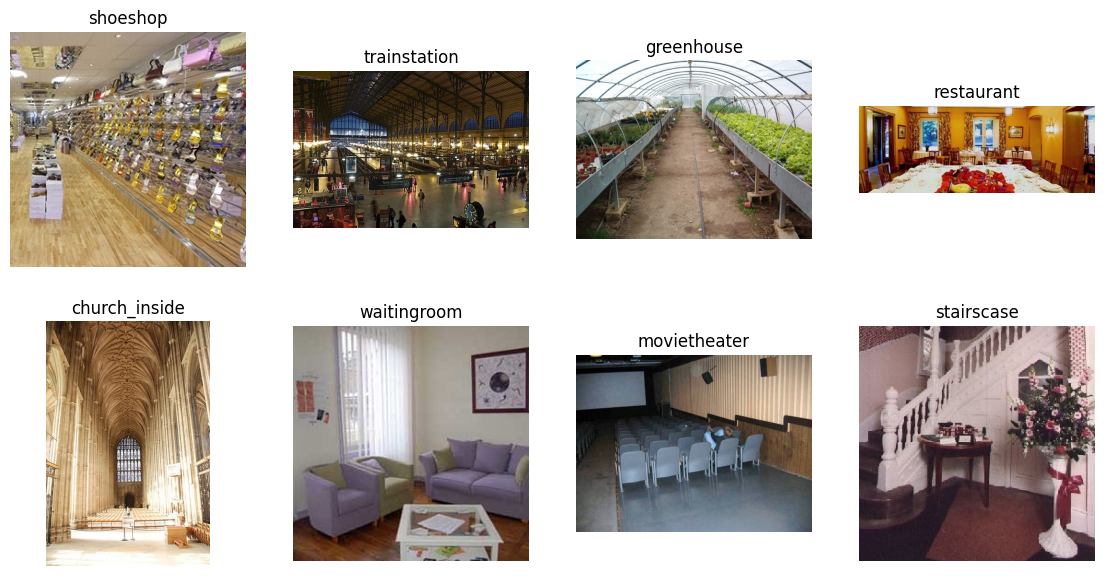

In [5]:
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
root = os.environ['DATA_ROOT']
df = pd.read_csv(f'{root}/train.csv')
print(df.shape)                        # 多少行、多少列
print(df['label'].value_counts().describe())   # 每个类别有多少张图

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), df.sample(8, random_state=0).iterrows()):
    ax.imshow(Image.open(f"{root}/images/{r.file_path}"))
    ax.set_title(r.label); ax.axis('off')
plt.show()

In [6]:
import timm
m = timm.create_model('resnet50.a1_in1k', pretrained=True, num_classes=0)
print(sum(p.numel() for p in m.parameters()))   # 参数总数
print(m)  # 层的结构,很长,往下滚动看看

23508032
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (act1): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act1): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (drop_block): Identity()
      (act2): ReLU(inplace=True)
      (aa): Identity()
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, af

In [7]:
import numpy as np
X = np.load(f"{root}/cache/resnet50.a1_in1k_train.npy")
print(X.shape)     # (5327, 2048)
print(X[0][:10])   # 第一张图的前 10 个数字

(5327, 2048)
[0.12757279 0.         0.00985841 0.         0.31281698 0.
 0.05564775 0.         0.00737261 0.        ]


In [43]:
!python src/linear_probe.py --C 0.01 --name C0.01
!python src/linear_probe.py --C 0.1  --name C0.1

!python src/summarize.py

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
python3: can't open file 'src/linear_probe.py': [Errno 2] No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
python3: can't open file 'src/linear_probe.py': [Errno 2] No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
python3: can't open file 'src/summarize.py': [Errno 2] No such file or directory


In [ ]:
!python src/linear_probe.py --C 0.003 --name C0.003
!python src/linear_probe.py --C 0.001 --name C0.001

val_acc (fold 0) = 0.7786
saved results/runs/20261121-220846_Jerry_C0.003.json
val_acc (fold 0) = 0.7702
saved results/runs/20261121-220900_Jerry_C0.001.json


In [8]:
import torch, timm, numpy as np
from PIL import Image

dev = "cuda" if torch.cuda.is_available() else "cpu"
model = timm.create_model("resnet50.a1_in1k", pretrained=True, num_classes=0).eval().to(dev)
cfg = timm.data.resolve_data_config({}, model=model)
print(cfg)
tf = timm.data.create_transform(**cfg)

img = Image.open(f"{root}/images/{df.file_path[0]}").convert("RGB")
print("原图大小:", img.size)
x = tf(img)
print("预处理后:", x.shape)

with torch.no_grad():
    feat = model(x.unsqueeze(0).to(dev))
print("特征形状:", feat.shape)
print("和之前缓存的第一行差多少:", np.abs(feat.cpu().numpy()[0] - X[0]).max())

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.95, 'crop_mode': 'center'}
原图大小: (500, 335)
预处理后: torch.Size([3, 224, 224])
特征形状: torch.Size([1, 2048])
和之前缓存的第一行差多少: 1.847744e-06


In [9]:
folds = pd.read_csv('splits/folds.csv')
d = df.merge(folds, on='id')
print(d.head())
print(d['fold'].value_counts())

             id               file_path          label  fold
0  train_000001  train/train_000001.jpg        florist     1
1  train_000002  train/train_000002.jpg     stairscase     3
2  train_000003  train/train_000003.jpg      tv_studio     1
3  train_000004  train/train_000004.jpg        bedroom     0
4  train_000005  train/train_000005.jpg  jewelleryshop     4
fold
1    1066
0    1066
3    1065
4    1065
2    1065
Name: count, dtype: int64


In [10]:
tr = (d['fold'] != 0).values   # 非 fold 0 的作训练
va = (d['fold'] == 0).values   # fold 0 的作验证
print(tr.sum(), va.sum())      # 训练多少张、验证多少张


4261 1066


In [11]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X[tr])
print("标准化前:", X[tr][:, :3].mean(0), X[tr][:, :3].std(0))
Xtr = sc.transform(X[tr])
print("标准化后:", Xtr[:, :3].mean(0), Xtr[:, :3].std(0))

标准化前: [0.04080398 0.03114717 0.05829112] [0.10523687 0.06619093 0.10020094]
标准化后: [9.5401006e-08 2.6426218e-07 1.2030038e-08] [1.0000118  0.9999979  0.99999654]


In [12]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(C=1.0, max_iter=2000).fit(Xtr, d['label'][tr])

In [13]:
pred = clf.predict(sc.transform(X[va]))
acc = (pred == d['label'][va]).mean()
print(acc)

0.7711069418386491


In [14]:
val = d[va].copy()
val['pred'] = pred
wrong = val[val['pred'] != val['label']]
print(len(wrong), "张答错")
print(wrong.groupby(['label', 'pred']).size().sort_values(ascending=False).head(10))


244 张答错
label           pred        
auditorium      concert_hall    5
children_room   kindergarden    4
deli            bakery          3
                grocerystore    3
bedroom         livingroom      3
airport_inside  trainstation    3
dining_room     kitchen         3
office          computerroom    3
library         videostore      3
movietheater    auditorium      3
dtype: int64


In [15]:
!python src/extract_features.py --model convnext_base.fb_in1k
!python src/linear_probe.py --model convnext_base.fb_in1k --C 0.01 --name convnext_C0.01
!python src/summarize.py

train: 100% 84/84 [00:58<00:00,  1.44it/s]
test: 100% 21/21 [00:16<00:00,  1.30it/s]
val_acc (fold 0) = 0.8124
saved results/runs/20261123-021623_Jerry_convnext_C0.01.json
          name  user                 model    C  fold  seed  val_acc            time
convnext_C0.01 Jerry convnext_base.fb_in1k 0.01     0    42 0.812383 20261123-021623
      baseline Jerry      resnet50.a1_in1k 1.00     0    42 0.771107 20261123-021349


In [16]:
!git fetch origin && git checkout Jerry-Experiment
#!python src/finetune.py --model convnext_base.fb_in1k --epochs 10 --name ft_convnext

branch 'Jerry-Experiment' set up to track 'origin/Jerry-Experiment'.
Switched to a new branch 'Jerry-Experiment'


In [17]:
!python src/finetune.py --model convnext_base.fb_in1k --epochs 10 --img 288 --bs 16 --name ft_convnext_288

Traceback (most recent call last):
  File "/content/repo/src/finetune.py", line 18, in <module>
    import timm
  File "/usr/local/lib/python3.13/dist-packages/timm/__init__.py", line 8, in <module>
    from .models import (
    ...<9 lines>...
    )
  File "/usr/local/lib/python3.13/dist-packages/timm/models/__init__.py", line 1, in <module>
    from .beit import *
  File "/usr/local/lib/python3.13/dist-packages/timm/models/beit.py", line 72, in <module>
    from ._builder import build_model_with_cfg
  File "/usr/local/lib/python3.13/dist-packages/timm/models/_builder.py", line 14, in <module>
    from timm.models._hub import has_hf_hub, download_cached_file, check_cached_file, load_state_dict_from_hf, \
        load_state_dict_from_path, load_custom_from_hf
  File "/usr/local/lib/python3.13/dist-packages/timm/models/_hub.py", line 36, in <module>
    from huggingface_hub import HfApi, hf_hub_download, model_info
  File "<frozen importlib._bootstrap>", line 1429, in _handle_fromlist
 

In [ ]:
import shutil
shutil.copy('/content/data/checkpoints/ft_convnext_288.pt', '/content/drive/MyDrive/daml-indoor67/checkpoints/')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/daml-indoor67/checkpoints/'

In [ ]:
import os, shutil
from google.colab import drive

if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')

dst = '/content/drive/MyDrive/daml-indoor67/checkpoints'
os.makedirs(dst, exist_ok=True)
shutil.copy('/content/data/checkpoints/ft_convnext_288.pt', dst)
!ls -lh {dst}

Mounted at /content/drive
total 669M
-rw------- 1 root root 335M Nov 22 22:04 ft_convnext_288.pt
-rw------- 1 root root 335M Nov 21 23:02 ft_convnext.pt


In [18]:
!git pull

Already up to date.


In [19]:
!python src/finetune.py --model convnext_base.fb_in1k --img 288 --eval_ckpt /content/data/checkpoints/ft_convnext_288.pt --tta --name ev_288_tta

Traceback (most recent call last):
  File "/content/repo/src/finetune.py", line 150, in <module>
    model.load_state_dict(torch.load(a.eval_ckpt, map_location=dev))
                          ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/serialization.py", line 1565, in load
    with _open_file_like(f, "rb") as opened_file:
         ~~~~~~~~~~~~~~~^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/serialization.py", line 795, in _open_file_like
    return _open_file(name_or_buffer, mode)
  File "/usr/local/lib/python3.13/dist-packages/torch/serialization.py", line 776, in __init__
    super().__init__(open(name, mode))  # noqa: SIM115
                     ~~~~^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: '/content/data/checkpoints/ft_convnext_288.pt'


In [20]:
!python src/finetune.py --model convnext_base.fb_in1k --epochs 10 --img 288 --bs 16 --fold -1 --tta --name ft_convnext_288_full

epoch 1/10  train_loss 2.808  (141s)
epoch 2/10  train_loss 1.211  (138s)
epoch 3/10  train_loss 0.955  (138s)
epoch 4/10  train_loss 0.837  (138s)
epoch 5/10  train_loss 0.802  (138s)
epoch 6/10  train_loss 0.779  (138s)
epoch 7/10  train_loss 0.768  (138s)
epoch 8/10  train_loss 0.760  (138s)
epoch 9/10  train_loss 0.756  (138s)
epoch 10/10  train_loss 0.754  (138s)
weights -> /content/data/checkpoints/ft_convnext_288_full.pt 
wrote submissions/20261123-0241_ft_convnext_288_full.csv


In [22]:
import os, shutil
from google.colab import drive
if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
dst = '/content/drive/MyDrive/daml-indoor67/checkpoints/'
os.makedirs(dst, exist_ok=True)
shutil.copy('/content/data/checkpoints/ft_convnext_288_full.pt', dst)

Mounted at /content/drive


'/content/drive/MyDrive/daml-indoor67/checkpoints/ft_convnext_288_full.pt'

In [23]:
from google.colab import files
files.download('submissions/20261123-0241_ft_convnext_288_full.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
!git pull

remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 6 (delta 4), reused 6 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 979 bytes | 489.00 KiB/s, done.
From https://github.com/JerNB/daml-indoor67
   b48b5b8..964da10  Jerry-Experiment -> origin/Jerry-Experiment
Updating b48b5b8..964da10
Fast-forward
 src/finetune.py | 22 +++++++++++++---------
 1 file changed, 13 insertions(+), 9 deletions(-)
